In [1]:

print("Welcome to EconoCausal EDA!")
      
      

Welcome to EconoCausal EDA!


In [5]:

import pandas as pd


In [6]:

df = pd.read_csv("Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv")


In [7]:

df.head()


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [8]:

print(df.shape)


(64000, 12)


In [9]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   recency          64000 non-null  int64  
 1   history_segment  64000 non-null  str    
 2   history          64000 non-null  float64
 3   mens             64000 non-null  int64  
 4   womens           64000 non-null  int64  
 5   zip_code         64000 non-null  str    
 6   newbie           64000 non-null  int64  
 7   channel          64000 non-null  str    
 8   segment          64000 non-null  str    
 9   visit            64000 non-null  int64  
 10  conversion       64000 non-null  int64  
 11  spend            64000 non-null  float64
dtypes: float64(2), int64(6), str(4)
memory usage: 5.9 MB


**Dataset Structure and Data Types**

The Hillstrom MineThatData email marketing dataset contains 64,000 rows and 12 columns, occupying approximately 5.9 MB of memory. The dataset includes numerical, categorical, and indicator variables. All columns contain 64,000 non-null values, suggesting that no missing values are detected during the initial inspection. Further data quality checks are required to identify duplicates, invalid values, and inconsistencies.

In [11]:

df.columns.tolist()



['recency',
 'history_segment',
 'history',
 'mens',
 'womens',
 'zip_code',
 'newbie',
 'channel',
 'segment',
 'visit',
 'conversion',
 'spend']

In [12]:

df.isnull().sum()


recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

**Missing Value Analysis**

The dataset was examined for missing values using pandas. All 12 columns contain zero missing values across 64,000 records. Therefore, no missing-value imputation or deletion is required based on this check. Further data quality checks will be performed to identify duplicate records and potentially invalid values.

In [13]:

df.duplicated().sum()


np.int64(6562)

In [15]:
df[df.duplicated()].head()

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
149,2,1) $0 - $100,29.99,0,1,Surburban,0,Phone,Mens E-Mail,0,0,0.0
167,7,1) $0 - $100,29.99,1,0,Surburban,1,Web,Womens E-Mail,0,0,0.0
526,10,1) $0 - $100,29.99,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0
654,10,1) $0 - $100,29.99,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0
792,9,1) $0 - $100,29.99,0,1,Surburban,0,Phone,No E-Mail,0,0,0.0


In [16]:
df["segment"].value_counts()

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

In [17]:
df["segment"].unique()

<StringArray>
['Womens E-Mail', 'No E-Mail', 'Mens E-Mail']
Length: 3, dtype: str

In [18]:
df[["visit", "conversion"]].value_counts().sort_index()

visit  conversion
0      0             54606
1      0              8816
       1               578
Name: count, dtype: int64

In [19]:
df["visit"].unique()

array([0, 1])

In [20]:
df["conversion"].unique()


array([0, 1])

In [21]:
df["spend"].describe()

count    64000.000000
mean         1.050908
std         15.036448
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        499.000000
Name: spend, dtype: float64

In [22]:
(df["spend"] > 0).sum()


np.int64(578)

In [23]:
(df["conversion"] == (df["spend"] > 0)).all()

np.True_

In [24]:
df["recency"].describe()

count    64000.000000
mean         5.763734
std          3.507592
min          1.000000
25%          2.000000
50%          6.000000
75%          9.000000
max         12.000000
Name: recency, dtype: float64

In [25]:
df["recency"].unique()

array([10,  6,  7,  9,  2,  1,  5,  4,  3, 11, 12,  8])

In [26]:
df["history_segment"].value_counts()

history_segment
1) $0 - $100        22970
2) $100 - $200      14254
3) $200 - $350      12289
4) $350 - $500       6409
5) $500 - $750       4911
6) $750 - $1,000     1859
7) $1,000 +          1308
Name: count, dtype: int64

In [27]:
df["history_segment"].unique()

<StringArray>
[  '2) $100 - $200',   '3) $200 - $350',   '5) $500 - $750',
     '1) $0 - $100', '6) $750 - $1,000',   '4) $350 - $500',
      '7) $1,000 +']
Length: 7, dtype: str

In [28]:
df["history"].describe()

count    64000.000000
mean       242.085656
std        256.158608
min         29.990000
25%         64.660000
50%        158.110000
75%        325.657500
max       3345.930000
Name: history, dtype: float64

In [29]:
df.groupby("history_segment")["history"].agg(["min", "max"])

,min,max
history_segment,,
1) $0 - $100,29.99,99.99
2) $100 - $200,100.00,199.98
3) $200 - $350,200.00,349.96
4) $350 - $500,350.01,499.95
5) $500 - $750,500.00,749.79
"6) $750 - $1,000",750.01,999.75
"7) $1,000 +",1000.15,3345.93


In [30]:
df["channel"].value_counts()

channel
Web             28217
Phone           28021
Multichannel     7762
Name: count, dtype: int64

In [31]:
df["channel"].unique()

<StringArray>
['Phone', 'Web', 'Multichannel']
Length: 3, dtype: str

In [32]:
df["zip_code"].value_counts()


zip_code
Surburban    28776
Urban        25661
Rural         9563
Name: count, dtype: int64

In [33]:
df["zip_code"].unique()

<StringArray>
['Surburban', 'Rural', 'Urban']
Length: 3, dtype: str

In [34]:
df["mens"].value_counts()

mens
1    35266
0    28734
Name: count, dtype: int64

In [35]:
df["mens"].unique()

array([1, 0])

In [36]:
df["womens"].value_counts()

womens
1    35182
0    28818
Name: count, dtype: int64

In [37]:
df["womens"].unique()

array([0, 1])

In [38]:
df["newbie"].value_counts()

newbie
1    32144
0    31856
Name: count, dtype: int64

In [39]:
df["newbie"].unique()

array([0, 1])

In [40]:
df.groupby("segment")["visit"].mean() * 100

segment
Mens E-Mail      18.275684
No E-Mail        10.616728
Womens E-Mail    15.140038
Name: visit, dtype: float64

In [41]:
df.groupby("segment")["conversion"].mean() * 100

segment
Mens E-Mail      1.253109
No E-Mail        0.572609
Womens E-Mail    0.883714
Name: conversion, dtype: float64

In [42]:
df.groupby("segment")["spend"].mean()

segment
Mens E-Mail      1.422617
No E-Mail        0.652789
Womens E-Mail    1.077202
Name: spend, dtype: float64

In [43]:
df.groupby("segment")["conversion"].sum()


segment
Mens E-Mail      267
No E-Mail        122
Womens E-Mail    189
Name: conversion, dtype: int64

In [44]:
df.groupby("segment")["visit"].sum()

segment
Mens E-Mail      3894
No E-Mail        2262
Womens E-Mail    3238
Name: visit, dtype: int64

In [45]:
df.groupby("segment").apply(
    lambda group: group["conversion"].sum() / group["visit"].sum() * 100,
    include_groups=False
)

segment
Mens E-Mail      6.856703
No E-Mail        5.393457
Womens E-Mail    5.836936
dtype: float64

In [46]:
df.groupby("segment")["spend"].sum()

segment
Mens E-Mail      30311.69
No E-Mail        13908.33
Womens E-Mail    23038.11
Name: spend, dtype: float64

In [48]:
segment_summary = df.groupby("segment").agg(
    customers=("segment", "size"),
    visits=("visit", "sum"),
    purchases=("conversion", "sum"),
    total_spend=("spend", "sum")
)

display(segment_summary)

,customers,visits,purchases,total_spend
segment,,,,
Mens E-Mail,21307,3894,267,30311.69
No E-Mail,21306,2262,122,13908.33
Womens E-Mail,21387,3238,189,23038.11


In [49]:
segment_summary["visit_rate_pct"] = (
    segment_summary["visits"] / segment_summary["customers"] * 100
)

display(segment_summary)

,customers,visits,purchases,total_spend,visit_rate_pct
segment,,,,,
Mens E-Mail,21307,3894,267,30311.69,18.275684
No E-Mail,21306,2262,122,13908.33,10.616728
Womens E-Mail,21387,3238,189,23038.11,15.140038


In [50]:
segment_summary["purchase_rate_pct"] = (
    segment_summary["purchases"] / segment_summary["customers"] * 100
)

display(segment_summary)

,customers,visits,purchases,total_spend,visit_rate_pct,purchase_rate_pct
segment,,,,,,
Mens E-Mail,21307,3894,267,30311.69,18.275684,1.253109
No E-Mail,21306,2262,122,13908.33,10.616728,0.572609
Womens E-Mail,21387,3238,189,23038.11,15.140038,0.883714


In [51]:
segment_summary["avg_spend_per_customer"] = (
    segment_summary["total_spend"] / segment_summary["customers"]
)

display(segment_summary)

,customers,visits,purchases,total_spend,visit_rate_pct,purchase_rate_pct,avg_spend_per_customer
segment,,,,,,,
Mens E-Mail,21307,3894,267,30311.69,18.275684,1.253109,1.422617
No E-Mail,21306,2262,122,13908.33,10.616728,0.572609,0.652789
Womens E-Mail,21387,3238,189,23038.11,15.140038,0.883714,1.077202


In [52]:
df.groupby("segment")["conversion"].mean().mul(100).round(2)


segment
Mens E-Mail      1.25
No E-Mail        0.57
Womens E-Mail    0.88
Name: conversion, dtype: float64

In [53]:
segment_summary["purchase_rate_among_visitors_pct"] = (
    segment_summary["purchases"] / segment_summary["visits"] * 100
)

display(
    segment_summary[
        ["visits", "purchases", "purchase_rate_among_visitors_pct"]
    ].round(2)
)


,visits,purchases,purchase_rate_among_visitors_pct
segment,,,
Mens E-Mail,3894,267,6.86
No E-Mail,2262,122,5.39
Womens E-Mail,3238,189,5.84


In [55]:
segment_summary["visit_rate_pct"].plot(
    kind="bar",
    title="Visit Rate by Email Segment",
    xlabel="Email Segment",
    ylabel="Visit Rate (%)",
    rot=0
)

import matplotlib.pyplot as plt
plt.show()

ImportError: matplotlib is required for plotting when the default backend "matplotlib" is selected.

In [56]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 5.1 MB/s eta 0:00:02
   ------- -------------------------------- 1.8/9.3 MB 4.3 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/9.3 MB 3.9 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.3 MB 4.1 MB/s eta 0:00:02
   ------------------- -------------------- 4.5/9.3 MB 4.0 MB/s eta 0:00:02
   --------------------- ------------------ 5.0/9.3 MB 3.9 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 3.8 MB/s eta 0:00:01
   ------------------------------ --------- 7.1/9.3 MB 4.0 MB/s eta 0:00:01
   -------------------------------- ------- 7.6/9.3 MB 3.9 MB/s eta 0:00:01
   ------------------------------------- -- 8.7/9.3 MB 4.0 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 3.9 MB/s  0:00:02
Using cached cycler-0.12.1-py3-non


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


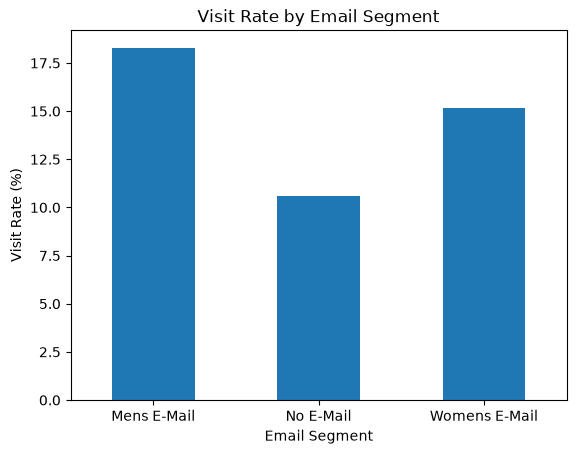

In [57]:
segment_summary["visit_rate_pct"].plot(
    kind="bar",
    title="Visit Rate by Email Segment",
    xlabel="Email Segment",
    ylabel="Visit Rate (%)",
    rot=0
)

import matplotlib.pyplot as plt
plt.show()

**Observation:** The Mens E-Mail segment has the highest visit rate (18.28%), followed by Womens E-Mail (15.14%) and No E-Mail (10.62%). The two email segments show higher observed visit rates than the no-email segment. These descriptive results alone do not establish that the emails caused the differences.

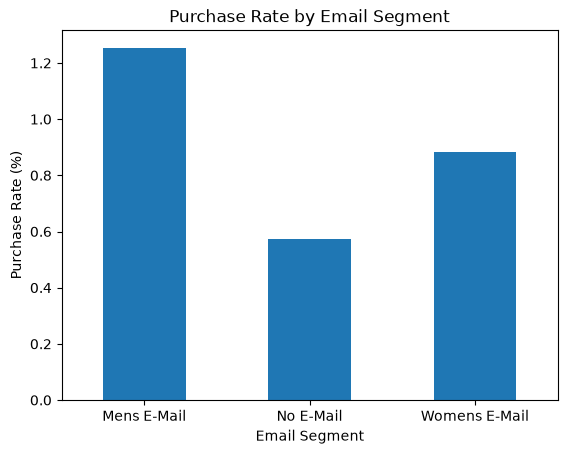

In [58]:
segment_summary["purchase_rate_pct"].plot(
    kind="bar",
    title="Purchase Rate by Email Segment",
    xlabel="Email Segment",
    ylabel="Purchase Rate (%)",
    rot=0
)

plt.show()

**Observation:** The Mens E-Mail segment has the highest purchase rate (1.25%), followed by Womens E-Mail (0.88%) and No E-Mail (0.57%). Although the email segments have higher observed purchase rates, this comparison alone does not prove that the emails caused the difference.

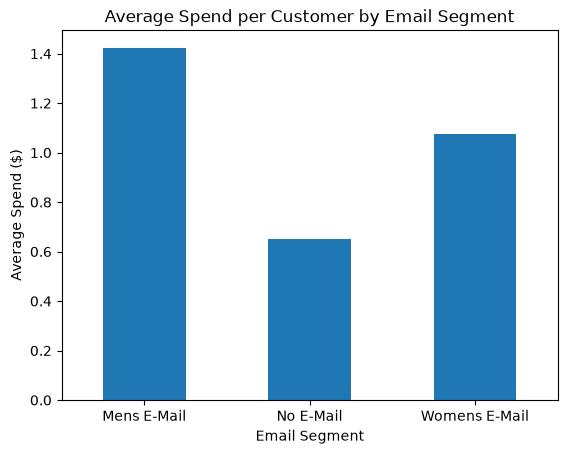

In [59]:
segment_summary["avg_spend_per_customer"].plot(
    kind="bar",
    title="Average Spend per Customer by Email Segment",
    xlabel="Email Segment",
    ylabel="Average Spend ($)",
    rot=0
)

plt.show()

**Observation:** The Mens E-Mail segment has the highest average spend per customer ($1.42), followed by Womens E-Mail ($1.08) and No E-Mail ($0.65). Since this average includes all customers, including those who spent $0, it provides a measure of spending per customer across each segment. The observed differences do not, by themselves, establish a causal effect of the emails.

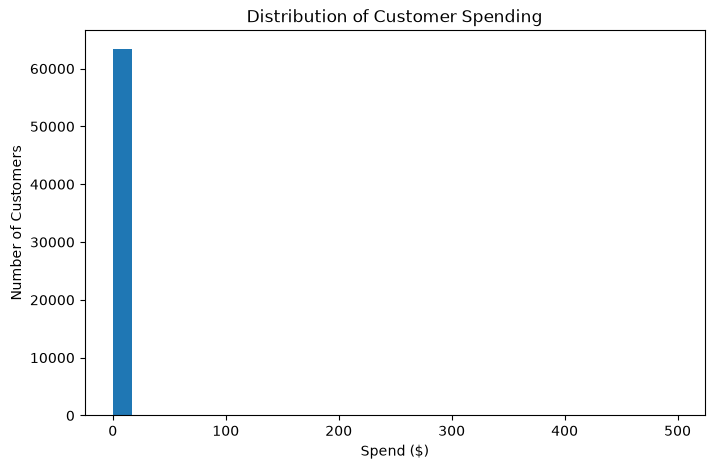

In [60]:
plt.figure(figsize=(8, 5))

plt.hist(df["spend"], bins=30)

plt.title("Distribution of Customer Spending")
plt.xlabel("Spend ($)")
plt.ylabel("Number of Customers")

plt.show()

In [64]:
print("Minimum spend:", df["spend"].min())
print("Maximum spend:", df["spend"].max())
print("Number of customers:", len(df))

Minimum spend: 0.0
Maximum spend: 499.0
Number of customers: 64000


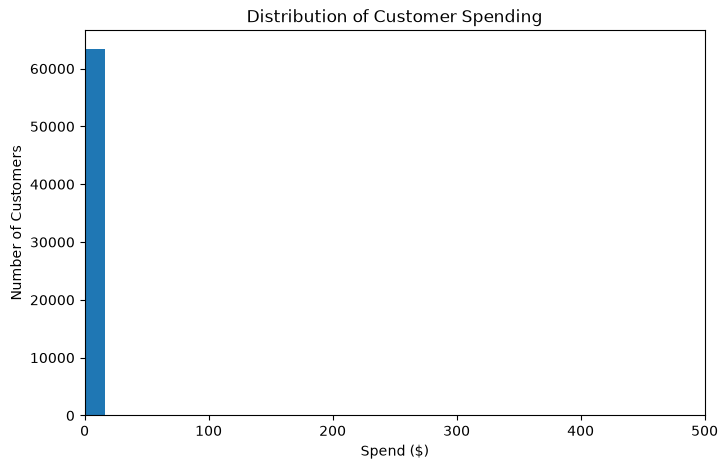

In [66]:
plt.figure(figsize=(8, 5))

plt.hist(df["spend"], bins=30, range=(0, 500))

plt.title("Distribution of Customer Spending")
plt.xlabel("Spend ($)")
plt.ylabel("Number of Customers")
plt.xlim(0, 500)

plt.show()

In [67]:
print(type(df["spend"]))
print(df["spend"].nunique())
print(plt)

<class 'pandas.Series'>
429
<module 'matplotlib.pyplot' from 'c:\\Users\\Arshiya\\OneDrive\\Desktop\\EconoCausal\\.venv\\Lib\\site-packages\\matplotlib\\pyplot.py'>


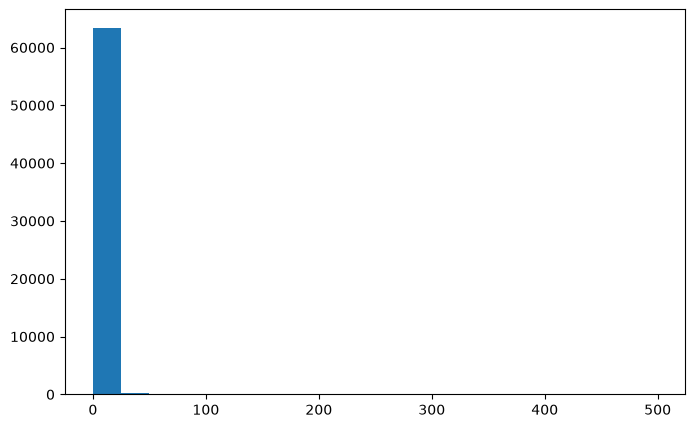

In [69]:
plt.figure(figsize=(8, 5))
plt.hist(df["spend"], bins=20)
plt.show()

In [71]:
import numpy as np
counts, edges = np.histogram(df["spend"], bins=20)

print("Number of bins:", len(counts))
print("Bin counts:", counts)
print("Bin edges:", edges)

Number of bins: 20
Bin counts: [63422   210    67    66    48    35    33    26    18    16     7     6
     5     7     7     8     3     2     1    13]
Bin edges: [  0.    24.95  49.9   74.85  99.8  124.75 149.7  174.65 199.6  224.55
 249.5  274.45 299.4  324.35 349.3  374.25 399.2  424.15 449.1  474.05
 499.  ]


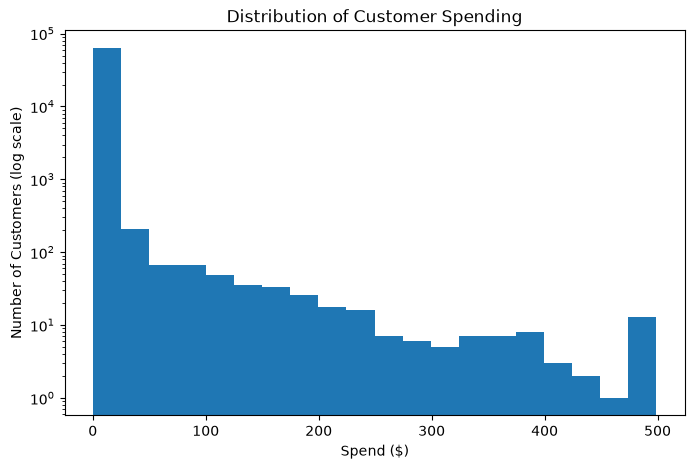

In [72]:
plt.figure(figsize=(8, 5))

plt.hist(df["spend"], bins=20)

plt.title("Distribution of Customer Spending")
plt.xlabel("Spend ($)")
plt.ylabel("Number of Customers (log scale)")
plt.yscale("log")

plt.show()

**Observation:** Customer spending is highly right-skewed. Most customers have zero spending, while a small proportion have positive spending, including a few customers with much higher values. The logarithmic y-axis makes the smaller frequency counts easier to see alongside the large concentration of low-spending customers.

In [73]:
df["recency"].value_counts().sort_index()

recency
1     8952
2     7537
3     5904
4     5077
5     4510
6     4605
7     4078
8     3495
9     6441
10    7565
11    3504
12    2332
Name: count, dtype: int64

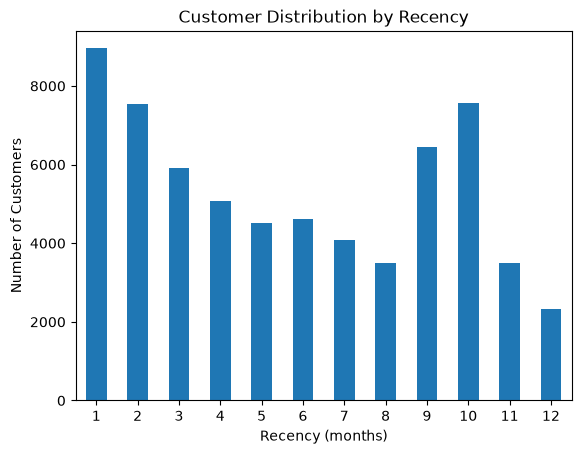

In [74]:
df["recency"].value_counts().sort_index().plot(
    kind="bar",
    title="Customer Distribution by Recency",
    xlabel="Recency (months)",
    ylabel="Number of Customers",
    rot=0
)

plt.show()

**Observation:** Customer counts vary across recency periods from 1 to 12 months. The highest count occurs at month 1, followed by a general decline through month 8. Counts rise noticeably in months 9 and 10 before decreasing again. This indicates that customer recency is unevenly distributed across the dataset. These counts describe the customer distribution but do not establish differences in email responsiveness or purchasing behavior.

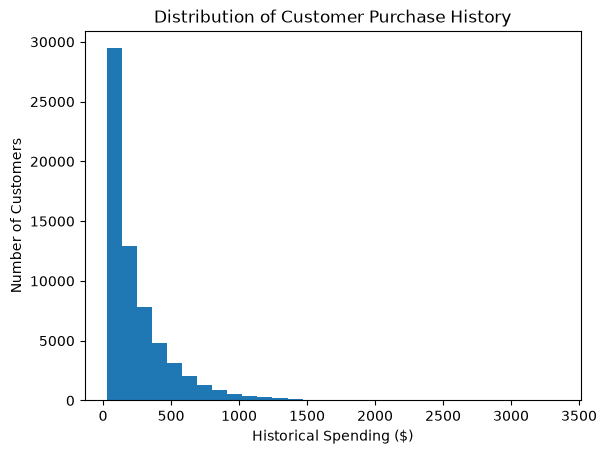

In [75]:
df["history"].plot(
    kind="hist",
    bins=30,
    title="Distribution of Customer Purchase History",
    xlabel="Historical Spending ($)",
    ylabel="Number of Customers"
)

plt.show()

**Observation:** The distribution of historical customer spending is right-skewed. Most customers have relatively low-to-moderate historical spending, while a smaller number have substantially higher values, creating a long right tail. The mean historical spending ($242.09) is greater than the median ($158.11), consistent with this skew. These patterns suggest substantial variation in customers' previous spending levels.

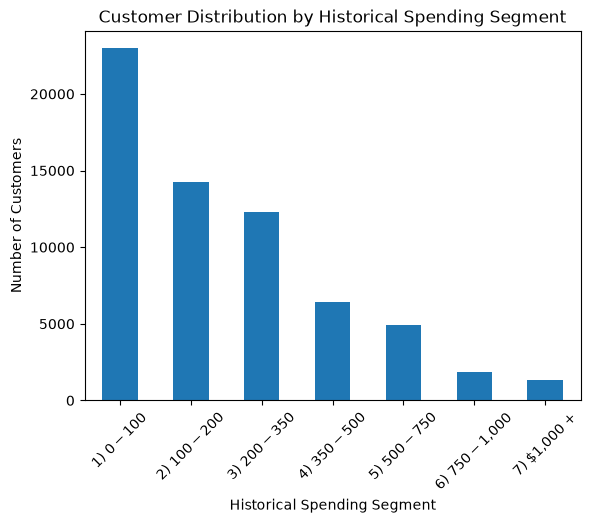

In [76]:
df["history_segment"].value_counts().sort_index().plot(
    kind="bar",
    title="Customer Distribution by Historical Spending Segment",
    xlabel="Historical Spending Segment",
    ylabel="Number of Customers",
    rot=45
)

plt.show()

**Observation:** Customer counts are concentrated in the lower historical-spending segments and generally decline as the spending brackets increase. The highest-spending categories contain fewer customers, indicating an uneven distribution of historical customer value. Further analysis of spending totals by segment would be needed to determine how much each group contributes to overall historical revenue.

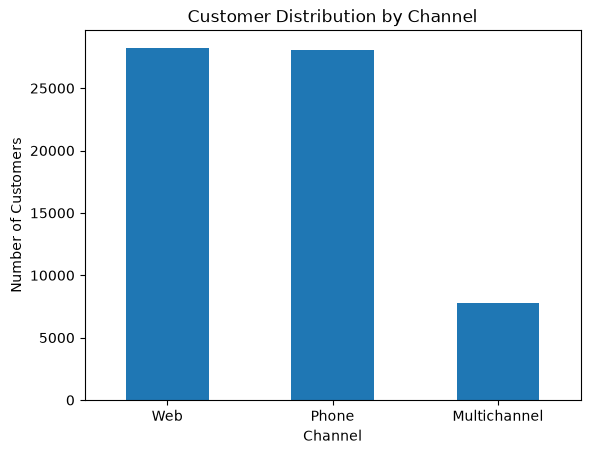

In [77]:
df["channel"].value_counts().plot(
    kind="bar",
    title="Customer Distribution by Channel",
    xlabel="Channel",
    ylabel="Number of Customers",
    rot=0
)

plt.show()

**Observation:** The Web channel (28,217 customers) and Phone channel (28,021 customers) account for nearly equal portions of the dataset. The Multichannel category contains substantially fewer customers (7,762). This indicates that the dataset has a much smaller representation of customers classified as Multichannel. These counts describe the distribution of channel categories but do not establish customer preferences or which channel performs best.

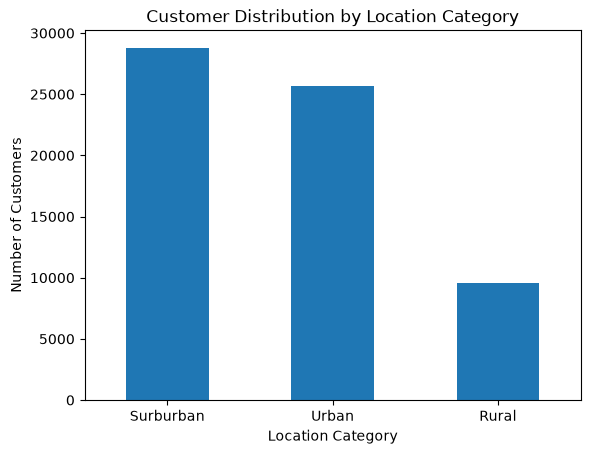

In [78]:
df["zip_code"].value_counts().plot(
    kind="bar",
    title="Customer Distribution by Location Category",
    xlabel="Location Category",
    ylabel="Number of Customers",
    rot=0
)

plt.show()

**Observation:** The `Surburban` category has the largest number of customers (28,776), followed by Urban (25,661) and Rural (9,563). Rural customers represent a smaller portion of the dataset. These counts describe the distribution of recorded location categories; further analysis is needed to determine whether customer outcomes differ across locations.

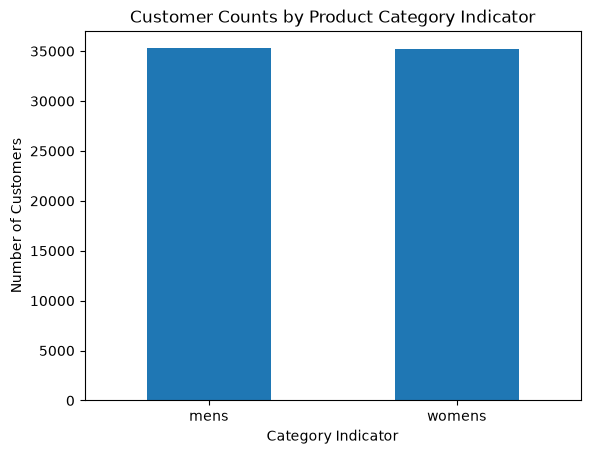

In [79]:
df[["mens", "womens"]].sum().plot(
    kind="bar",
    title="Customer Counts by Product Category Indicator",
    xlabel="Category Indicator",
    ylabel="Number of Customers",
    rot=0
)

plt.show()

**Observation:** The dataset contains 35,266 customers with `mens = 1` and 35,182 customers with `womens = 1`. The counts are very similar, suggesting that both indicators are well represented in the dataset. These indicators describe customer categories in the recorded data; they should not automatically be interpreted as mutually exclusive groups.

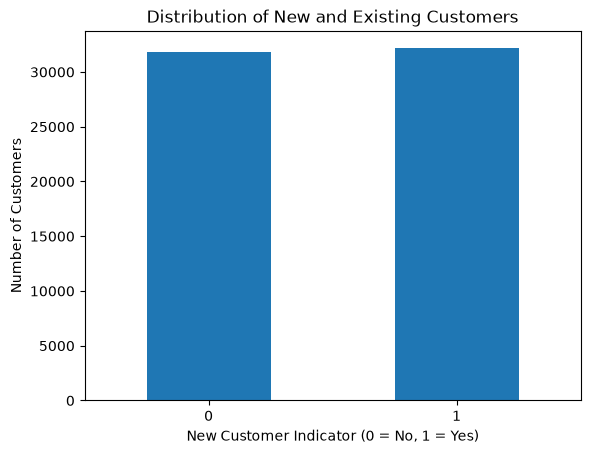

In [80]:
df["newbie"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribution of New and Existing Customers",
    xlabel="New Customer Indicator (0 = No, 1 = Yes)",
    ylabel="Number of Customers",
    rot=0
)

plt.show()

**Observation:** The dataset contains 32,144 customers with `newbie = 1` and 31,856 customers with `newbie = 0`. The two groups are represented in nearly equal numbers, with a slightly larger proportion of customers classified as new. This chart describes the distribution of the customer indicator; further analysis is needed to determine whether new and existing customers differ in their response to email campaigns or purchasing behavior.

In [81]:
visit_by_newbie = df.groupby("newbie")["visit"].mean() * 100

visit_by_newbie

newbie
0    17.306002
1    12.073793
Name: visit, dtype: float64

**Observation:** Existing customers (`newbie = 0`) have a visit rate of approximately 17.31%, compared with 12.07% for new customers (`newbie = 1`). This indicates that existing customers in the dataset visited the website at a higher rate than new customers. The difference is descriptive and does not establish that customer status caused the difference in visit behavior.

In [82]:
purchase_by_newbie = df.groupby("newbie")["conversion"].mean() * 100

purchase_by_newbie

newbie
0    1.010799
1    0.796416
Name: conversion, dtype: float64

**Observation:** The purchase rates for new and existing customers can be compared using the average of the binary `conversion` indicator, expressed as a percentage. This comparison helps describe differences in purchasing outcomes between the two groups. Any observed difference is descriptive and does not, by itself, establish a causal relationship.

In [83]:
spend_by_newbie = df.groupby("newbie")["spend"].mean()

spend_by_newbie

newbie
0    1.166053
1    0.936795
Name: spend, dtype: float64

**Observation:** Average spending per customer can be compared between new and existing customers using the mean of the `spend` column. Because customers who do not purchase have zero spending, this measure reflects spending across the entire customer group, not just customers who made a purchase. Any difference observed is descriptive and does not establish a causal relationship.

In [84]:
spend_by_newbie = df.groupby("newbie")["spend"].mean()

spend_by_newbie

newbie
0    1.166053
1    0.936795
Name: spend, dtype: float64

In [85]:
df.groupby("newbie")["conversion"].mean() * 100

newbie
0    1.010799
1    0.796416
Name: conversion, dtype: float64

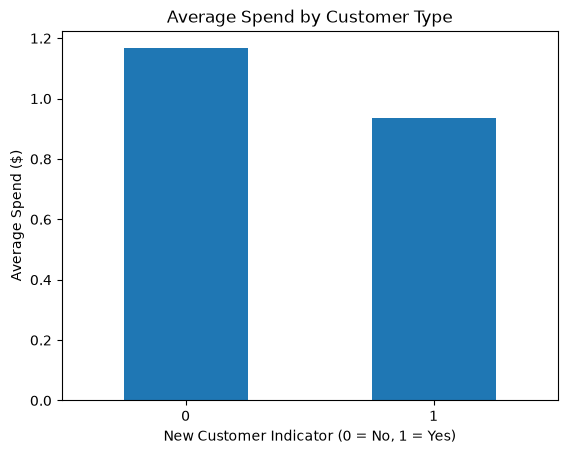

In [86]:
df.groupby("newbie")["spend"].mean().plot(
    kind="bar",
    title="Average Spend by Customer Type",
    xlabel="New Customer Indicator (0 = No, 1 = Yes)",
    ylabel="Average Spend ($)",
    rot=0
)

plt.show()

**Observation:** The chart indicates that existing customers (`newbie = 0`) have a higher average spend per customer ($1.17) than new customers (`newbie = 1`, $0.94). This suggests that existing customers in this dataset contribute more spending per customer on average. Customer retention may be worth exploring as a business strategy, although this comparison alone does not establish that retaining customers causes spending to increase.

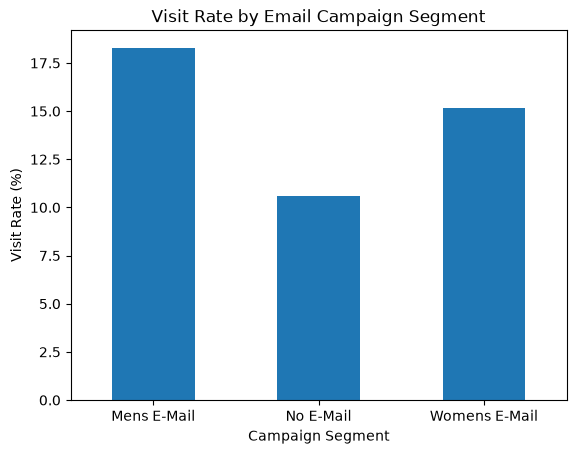

In [87]:
df.groupby("segment")["visit"].mean().mul(100).plot(
    kind="bar",
    title="Visit Rate by Email Campaign Segment",
    xlabel="Campaign Segment",
    ylabel="Visit Rate (%)",
    rot=0
)

plt.show()

**Observation:** The chart shows that the Men's E-Mail group has the highest visit rate, followed by the Women's E-Mail group, while the No E-Mail group has the lowest visit rate. The visit rates are approximately 18.28%, 15.14%, and 10.62%, respectively. This pattern is consistent with email campaigns increasing customer engagement, although the chart alone does not quantify the causal effect of each campaign.

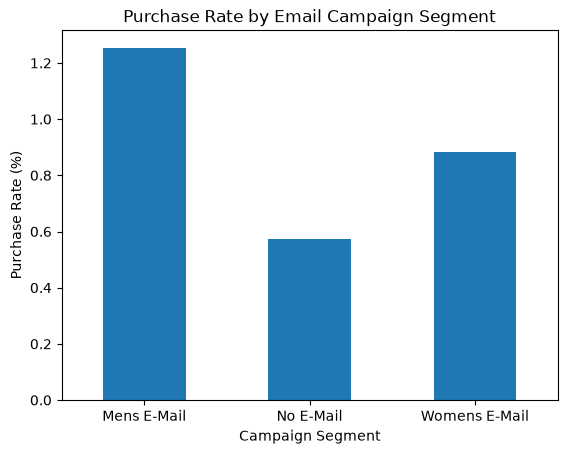

In [88]:
df.groupby("segment")["conversion"].mean().mul(100).plot(
    kind="bar",
    title="Purchase Rate by Email Campaign Segment",
    xlabel="Campaign Segment",
    ylabel="Purchase Rate (%)",
    rot=0
)

plt.show()

**Observation:** The Men's E-Mail group has the highest purchase rate (approximately 1.25%), followed by the Women's E-Mail group (0.88%), while the No E-Mail group has the lowest purchase rate (0.57%). This pattern suggests that the email campaign groups differ in their observed purchase outcomes, with the Men's E-Mail group showing the highest rate. Further statistical analysis can help quantify these differences and assess the campaigns' effects.

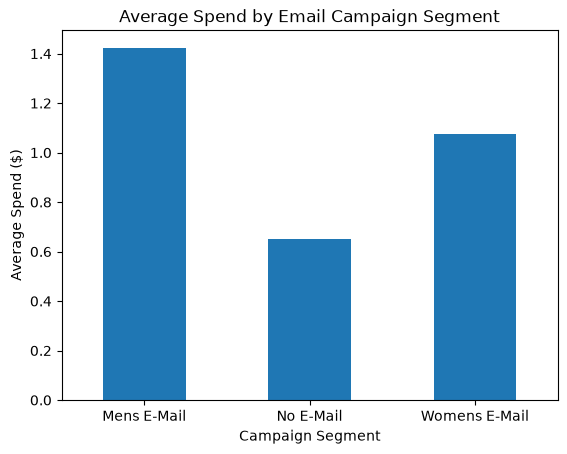

In [89]:
df.groupby("segment")["spend"].mean().plot(
    kind="bar",
    title="Average Spend by Email Campaign Segment",
    xlabel="Campaign Segment",
    ylabel="Average Spend ($)",
    rot=0
)

plt.show()

**Observation:** Average spending per customer is highest in the Men's E-Mail group (approximately $1.42), followed by the Women's E-Mail group ($1.08), while the No E-Mail group has the lowest average ($0.65). This pattern is consistent with email campaigns being associated with higher customer spending. Further analysis is needed to quantify the campaigns' causal effects.

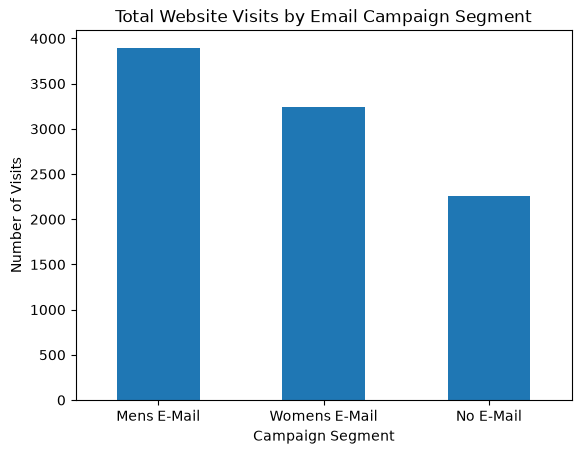

In [90]:
df.groupby("segment")["visit"].sum().sort_values(ascending=False).plot(
    kind="bar",
    title="Total Website Visits by Email Campaign Segment",
    xlabel="Campaign Segment",
    ylabel="Number of Visits",
    rot=0
)

plt.show()

**Observation:** Total website visits are highest in the Men's E-Mail group (3,894), followed by the Women's E-Mail group (3,238), while the No E-Mail group has the fewest visits (2,262). This pattern is consistent with higher website engagement among customers in the email campaign groups. Visit rates provide a fairer comparison because the three groups have slightly different customer counts.

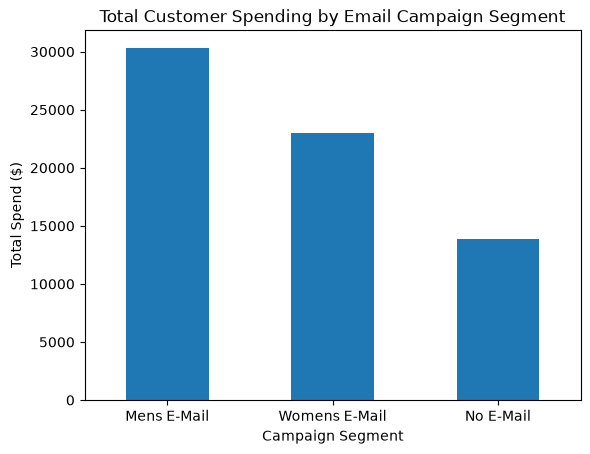

In [91]:
df.groupby("segment")["spend"].sum().sort_values(ascending=False).plot(
    kind="bar",
    title="Total Customer Spending by Email Campaign Segment",
    xlabel="Campaign Segment",
    ylabel="Total Spend ($)",
    rot=0
)

plt.show()

**Observation:** Total customer spending is highest in the Men's E-Mail group ($30,311.69), followed by the Women's E-Mail group ($23,038.11), while the No E-Mail group has the lowest total spending ($13,908.33). This pattern is consistent with higher overall spending in the email campaign groups. Comparing average spending per customer alongside total spending provides a more balanced view of campaign outcomes.

In [92]:
pd.crosstab(
    df["visit"],
    df["conversion"],
    margins=True,
    rownames=["Visited"],
    colnames=["Purchased"]
)

Purchased,0,1,All
Visited,,,
0,54606,0,54606
1,8816,578,9394
All,63422,578,64000


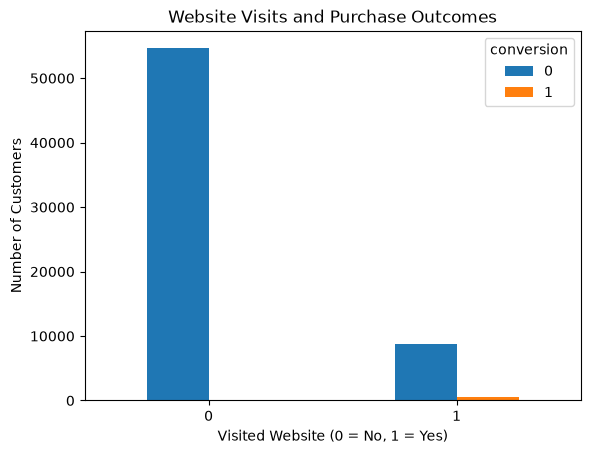

In [93]:
visit_purchase = pd.crosstab(df["visit"], df["conversion"])

visit_purchase.plot(
    kind="bar",
    title="Website Visits and Purchase Outcomes",
    xlabel="Visited Website (0 = No, 1 = Yes)",
    ylabel="Number of Customers",
    rot=0
)

plt.show()

**Observation:** The chart shows that all 578 recorded purchases occurred among customers who visited the website. However, most visitors (8,816 out of 9,394) did not make a purchase. Approximately 6.15% of visitors converted, compared with 0% of non-visitors. This indicates a strong association between website visits and purchases in the dataset, although it does not establish causation.

In [94]:
overall_conversion_rate = df["conversion"].mean() * 100

print(f"Overall conversion rate: {overall_conversion_rate:.2f}%")

Overall conversion rate: 0.90%


In [95]:
overall_visit_rate = df["visit"].mean() * 100

print(f"Overall visit rate: {overall_visit_rate:.2f}%")

Overall visit rate: 14.68%


In [96]:
visitors = df[df["visit"] == 1]

no_purchase_rate = (
    (visitors["conversion"] == 0).mean() * 100
)

print(f"Visitors who did not purchase: {no_purchase_rate:.2f}%")

Visitors who did not purchase: 93.85%


In [97]:
df.groupby("visit")["spend"].mean()


visit
0    0.00000
1    7.15969
Name: spend, dtype: float64

In [98]:
df.loc[
    (df["visit"] == 1) & (df["conversion"] == 1),
    "spend"
].mean()

np.float64(116.36354671280277)

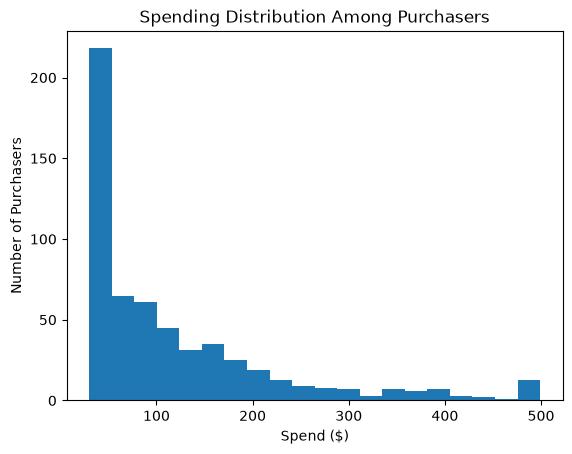

In [99]:
purchasers = df.loc[df["conversion"] == 1, "spend"]

purchasers.plot(
    kind="hist",
    bins=20,
    title="Spending Distribution Among Purchasers",
    xlabel="Spend ($)",
    ylabel="Number of Purchasers"
)

plt.show()

**Observation:** The spending distribution among purchasers is right-skewed. Most purchasers have relatively lower spending amounts, while a smaller number spend substantially more, creating a long right tail. This indicates variation in purchase value among customers. Further analysis of revenue contributions would be needed to determine how much total revenue comes from high-spending customers.

In [100]:
purchaser_spend = df.loc[df["conversion"] == 1, "spend"].sort_values(
    ascending=False
)

top_10_count = int(len(purchaser_spend) * 0.10)

top_10_revenue_share = (
    purchaser_spend.head(top_10_count).sum()
    / purchaser_spend.sum()
) * 100

print(f"Top 10% of purchasers' share of revenue: {top_10_revenue_share:.2f}%")

Top 10% of purchasers' share of revenue: 32.27%


In [101]:
purchaser_summary = df[df["conversion"] == 1].groupby("segment")["spend"].agg(
    ["count", "mean", "median", "sum"]
)

purchaser_summary

,count,mean,median,sum
segment,,,,
Mens E-Mail,267,113.526929,66.980,30311.69
No E-Mail,122,114.002705,88.365,13908.33
Womens E-Mail,189,121.894762,94.710,23038.11


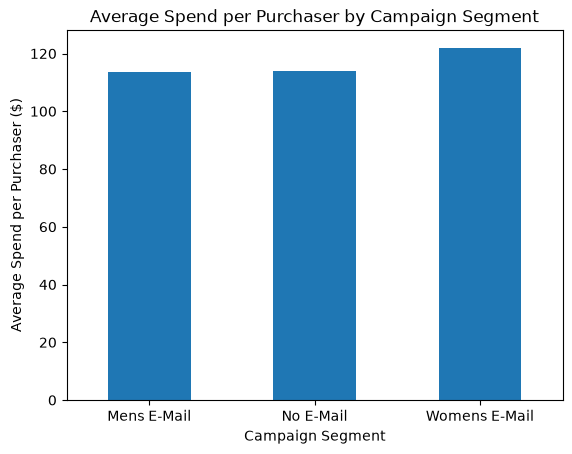

In [102]:
purchaser_summary["mean"].plot(
    kind="bar",
    title="Average Spend per Purchaser by Campaign Segment",
    xlabel="Campaign Segment",
    ylabel="Average Spend per Purchaser ($)",
    rot=0
)

plt.show()

**Observation:** Average spending per purchaser is relatively similar across the three campaign segments, ranging from approximately $113.53 to $121.89. The Women's E-Mail group has the highest average spending per purchaser, while the Men's E-Mail group has the highest number of purchasers. This suggests that campaign outcomes differ depending on whether we examine purchase frequency or purchase value.

In [103]:
numeric_df = df.select_dtypes(include="number")

numeric_df.corr().round(2)

,recency,history,mens,womens,newbie,visit,conversion,spend
recency,1.00,-0.25,-0.03,-0.03,-0.05,-0.07,-0.02,-0.02
history,-0.25,1.00,0.11,0.11,0.22,0.07,0.03,0.02
mens,-0.03,0.11,1.00,-0.82,0.02,0.01,0.00,0.01
womens,-0.03,0.11,-0.82,1.00,0.02,0.05,0.01,0.00
newbie,-0.05,0.22,0.02,0.02,1.00,-0.07,-0.01,-0.01
visit,-0.07,0.07,0.01,0.05,-0.07,1.00,0.23,0.17
conversion,-0.02,0.03,0.00,0.01,-0.01,0.23,1.00,0.73
spend,-0.02,0.02,0.01,0.00,-0.01,0.17,0.73,1.00


In [105]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


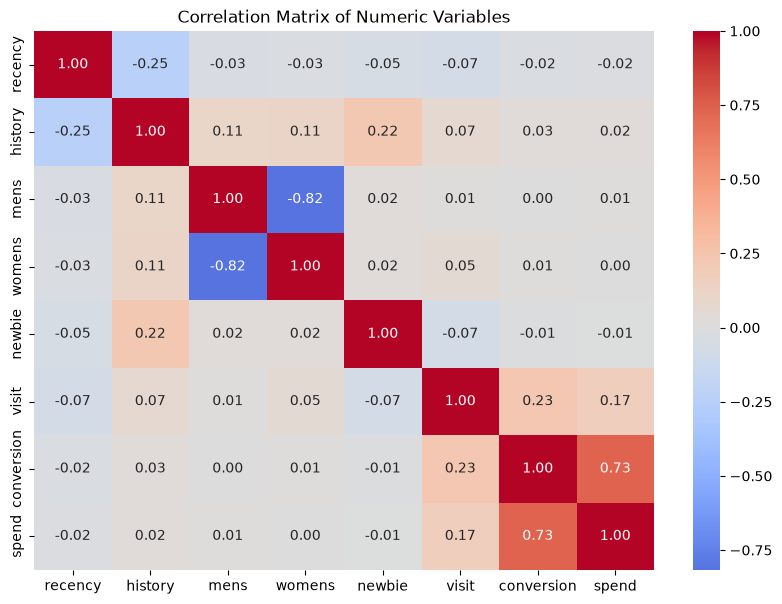

In [106]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Numeric Variables")
plt.show()

**Observation:** The correlation matrix shows that most numeric variables have weak linear relationships. The strongest positive correlation is between conversion and spend (0.73), which is expected because purchases are associated with positive spending. Website visits and conversions have a positive correlation (0.23), indicating that visiting and purchasing are associated in this dataset. However, correlation alone does not establish causation.

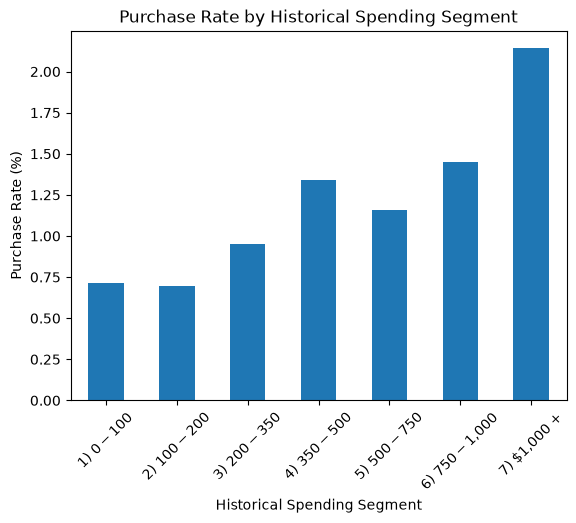

In [108]:
df.groupby("history_segment")["conversion"].mean().mul(100).plot(
    kind="bar",
    title="Purchase Rate by Historical Spending Segment",
    xlabel="Historical Spending Segment",
    ylabel="Purchase Rate (%)",
    rot=45
)

plt.show()

**Observation:** The chart compares purchase rates across historical spending segments. If higher-spending segments show higher purchase rates, this may indicate an association between customers' previous spending levels and their purchasing behavior in the campaign dataset. These customers may be worth examining further for retention and marketing strategies. However, the pattern should be confirmed from the plotted values, and the comparison alone does not establish causation.

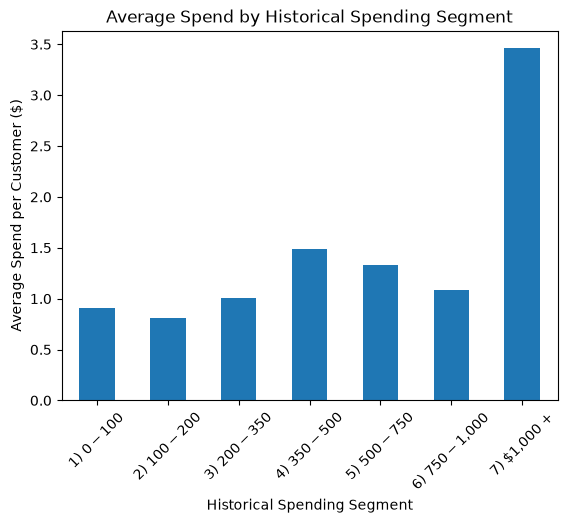

In [109]:
df.groupby("history_segment")["spend"].mean().plot(
    kind="bar",
    title="Average Spend by Historical Spending Segment",
    xlabel="Historical Spending Segment",
    ylabel="Average Spend per Customer ($)",
    rot=45
)

plt.show()

**Observation:** Average spending per customer generally increases across the historical spending segments, with the $1,000+ segment showing the highest average spend. This suggests that customers with higher historical spending also tend to spend more in the campaign dataset. These customers may be useful to examine for retention strategies, although the chart alone does not establish causation.

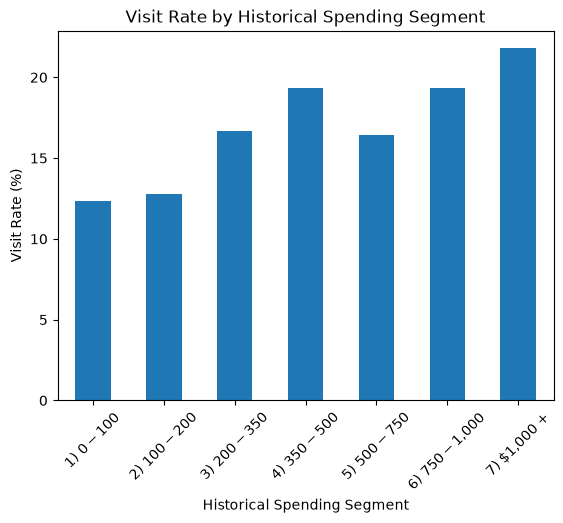

In [110]:
df.groupby("history_segment")["visit"].mean().mul(100).plot(
    kind="bar",
    title="Visit Rate by Historical Spending Segment",
    xlabel="Historical Spending Segment",
    ylabel="Visit Rate (%)",
    rot=45
)

plt.show()

**Observation:** Visit rates generally increase with historical spending, with higher-spending customer segments showing greater website engagement. This suggests that customers with a higher historical spending level may be more responsive to marketing campaigns. These customers could be worth examining as a target audience for future marketing strategies, although this chart alone does not establish causation.

In [111]:
df.isnull().sum()

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

In [112]:
df.dtypes

recency              int64
history_segment        str
history            float64
mens                 int64
womens               int64
zip_code               str
newbie               int64
channel                str
segment                str
visit                int64
conversion           int64
spend              float64
dtype: object

In [113]:
print("Dataset shape:", df.shape)
print("\nOverall visit rate (%):", round(df["visit"].mean() * 100, 2))
print("Overall purchase rate (%):", round(df["conversion"].mean() * 100, 2))
print("Total purchases:", df["conversion"].sum())
print("Total revenue ($):", round(df["spend"].sum(), 2))
print("Average spend per customer ($):", round(df["spend"].mean(), 2))

Dataset shape: (64000, 12)

Overall visit rate (%): 14.68
Overall purchase rate (%): 0.9
Total purchases: 578
Total revenue ($): 67258.13
Average spend per customer ($): 1.05


## Overall EDA Summary

The dataset contains **64,000 customer records and 12 variables**, with no missing values across the columns. The data includes customer characteristics, historical purchasing information, marketing campaign segments, website visits, conversions, and spending.

The overall website visit rate was **14.68%**, while the purchase rate was **0.90%**, resulting in 578 purchases. Total revenue was **$67,258.13**, and average spending per customer was **$1.05**.

Exploratory analysis showed differences across marketing campaign groups. The Men's E-Mail group had the highest visit rate, purchase rate, average spending per customer, and total revenue among the three groups. Historical spending segments also showed differences in customer engagement and spending patterns. Existing customers had higher average spending and purchase rates than new customers in this dataset.

Spending was highly right-skewed: most customers had zero spending, while a small proportion made purchases. Correlation analysis showed that most numerical variables had weak linear relationships, with a stronger positive correlation between conversion and spending, which is expected because purchases are associated with positive spending.

**Conclusion:** The EDA identifies useful patterns in customer engagement, purchasing behavior, and campaign performance. However, these are descriptive findings; they do not by themselves prove that an email campaign caused an increase in purchases or revenue. Further causal analysis is needed to estimate the incremental impact of each campaign.